# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [10]:
import random
import hashlib
import pandas as pd
import nltk
import string


ROLL_NO = 1024170314         # <-- your full roll number
NAME = "Aditya Kumar"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [11]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [12]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [13]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170314   Name: Aditya Kumar   Fingerprint: 48574208   Tickets: 16

Ticket_ID                                                                             Ticket_Text
      T01 I couldn't connect to the projector after the latest update. I don't know what changed.
      T02                                             I can't login and I didn't change anything.
      T03                                          The lms was working yesterday. This is urgent.
      T04             E-mail keeps asking for login while uploading the file. Can you check this?
      T05                                                   I tried again... still no response!!!
      T06                                        The LMS stopped responding. It worked yesterday.
      T07        LMS keeps disconnecting after restarting the system. I have tried several times!
      T08                        I couldn't connect to the e-mail during the lab. This is urgent.
      T09                         

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [14]:
import pandas as pd

processed = df["Ticket_Text"].apply(process_ticket).tolist()

summary = []

for ticket_id, result in zip(df["Ticket_ID"], processed):
    summary.append({
        "Ticket_ID": ticket_id,
        "Sentences": result["sentences"],
        "Tokens": result["tokens"],
        "Punctuation Tokens": result["punct"],
        "Stopwords": result["stops"],
        "Unique Tokens": sorted(set(result["tokens"])),
        "Final Tokens": result["final"]
    })

# TOTAL row
total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": sum(len(r["sentences"]) for r in processed),
    "Tokens": sum(len(r["tokens"]) for r in processed),
    "Punctuation Tokens": sum(len(r["punct"]) for r in processed),
    "Stopwords": sum(len(r["stops"]) for r in processed),
    "Unique Tokens": len(set(t for r in processed for t in r["tokens"])),
    "Final Tokens": sum(len(r["final"]) for r in processed)
}

summary.append(total_row)
display(pd.DataFrame(summary))

# Display the selected focus ticket
selected_ticket = FOCUS[0]
result = processed[df["Ticket_ID"].tolist().index(selected_ticket)]

print("\nSelected Ticket:", selected_ticket)
print("Ticket Text:", df.loc[df["Ticket_ID"] == selected_ticket,
                              "Ticket_Text"].iloc[0])
print("Actual Tokens:", result["tokens"])
print("Punctuation Tokens:", result["punct"])
print("Stopwords:", result["stops"])
print("Final Tokens:", result["final"])

,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,[I couldn't connect to the projector after the...,"[i, could, n't, connect, to, the, projector, a...","[., .]","[i, to, the, after, the, i, do, what]","[., after, changed, connect, could, do, i, kno...","[could, n't, connect, projector, latest, updat..."
1,T02,[I can't login and I didn't change anything.],"[i, ca, n't, login, and, i, did, n't, change, ...",[.],"[i, and, i, did]","[., and, anything, ca, change, did, i, login, ...","[ca, n't, login, n't, change, anything]"
2,T03,"[The lms was working yesterday., This is urgent.]","[the, lms, was, working, yesterday, ., this, i...","[., .]","[the, was, this, is]","[., is, lms, the, this, urgent, was, working, ...","[lms, working, yesterday, urgent]"
3,T04,[E-mail keeps asking for login while uploading...,"[e-mail, keeps, asking, for, login, while, upl...","[., ?]","[for, while, the, can, you, this]","[., ?, asking, can, check, e-mail, file, for, ...","[e-mail, keeps, asking, login, uploading, file..."
4,T05,"[I tried again... still no response!!, !]","[i, tried, again, ..., still, no, response, !,...","[..., !, !, !]","[i, again, no]","[!, ..., again, i, no, response, still, tried]","[tried, still, response]"
5,T06,"[The LMS stopped responding., It worked yester...","[the, lms, stopped, responding, ., it, worked,...","[., .]","[the, it]","[., it, lms, responding, stopped, the, worked,...","[lms, stopped, responding, worked, yesterday]"
6,T07,[LMS keeps disconnecting after restarting the ...,"[lms, keeps, disconnecting, after, restarting,...","[., !]","[after, the, i, have]","[!, ., after, disconnecting, have, i, keeps, l...","[lms, keeps, disconnecting, restarting, system..."
7,T08,[I couldn't connect to the e-mail during the l...,"[i, could, n't, connect, to, the, e-mail, duri...","[., .]","[i, to, the, during, the, this, is]","[., connect, could, during, e-mail, i, is, lab...","[could, n't, connect, e-mail, lab, urgent]"
8,T09,[I need Windows 11 by 5.30 p.m. today.],"[i, need, windows, 11, by, 5.30, p.m., today, .]",[.],"[i, by]","[., 11, 5.30, by, i, need, p.m., today, windows]","[need, windows, 11, 5.30, p.m., today]"
9,T10,[I can't open the wifi before the assignment d...,"[i, ca, n't, open, the, wifi, before, the, ass...","[., ?]","[i, the, before, the, is, there]","[., ?, another, assignment, before, ca, deadli...","[ca, n't, open, wifi, assignment, deadline, an..."



Selected Ticket: T11
Ticket Text: The printer has stopped syncing. The same problem occurs again.
Actual Tokens: ['the', 'printer', 'has', 'stopped', 'syncing', '.', 'the', 'same', 'problem', 'occurs', 'again', '.']
Punctuation Tokens: ['.', '.']
Stopwords: ['the', 'has', 'the', 'same', 'again']
Final Tokens: ['printer', 'stopped', 'syncing', 'problem', 'occurs']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [15]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code


import re

# ---------------------------------------------------------
# 1. Words longer than 5 letters
# ---------------------------------------------------------
long_words_pattern = r"\b[A-Za-z]{6,}\b"

# 2. All numbers, keeping decimals/versions whole
# Examples: 95.5, 2.0.1, 1,250, 5.30
numbers_pattern = r"\b\d+(?:[.,]\d+)*\b"

# 3. Capitalized words
capitalized_pattern = r"\b[A-Z][a-zA-Z]*\b"

# 4. Words starting with a vowel
vowel_words_pattern = r"\b[AEIOUaeiou][A-Za-z]*\b"


# ---------------------------------------------------------
# Apply extraction on raw tickets
# ---------------------------------------------------------
q2_results = []

for _, row in df.iterrows():
    text = row["Ticket_Text"]

    q2_results.append({
        "Ticket_ID": row["Ticket_ID"],
        "Long Words": re.findall(long_words_pattern, text),
        "Numbers": re.findall(numbers_pattern, text),
        "Capitalized Words": re.findall(capitalized_pattern, text),
        "Vowel Words": re.findall(vowel_words_pattern, text)
    })

q2_df = pd.DataFrame(q2_results)

display(q2_df)


# ---------------------------------------------------------
# Replace emails, URLs and phone numbers
# ---------------------------------------------------------

email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"

url_pattern = r"https?://[^\s]+|www\.[^\s]+"

phone_pattern = r"(?:\+91[\s-]?)?(?:\d{5}[\s-]?\d{5}|\d{4}[\s-]?\d{3}[\s-]?\d{4})"


def mask_contacts(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text


# Apply to raw tickets
df["Masked_Text"] = df["Ticket_Text"].apply(mask_contacts)

display(df[["Ticket_ID", "Ticket_Text", "Masked_Text"]])


# ---------------------------------------------------------
# Test patterns on TEST_LINES
# ---------------------------------------------------------

print("========== TEST_LINES ==========")

for i, text in enumerate(TEST_LINES, 1):
    print(f"\nTEST LINE {i}:")
    print(text)

    print("Long words:",
          re.findall(long_words_pattern, text))

    print("Numbers:",
          re.findall(numbers_pattern, text))

    print("Capitalized words:",
          re.findall(capitalized_pattern, text))

    print("Vowel words:",
          re.findall(vowel_words_pattern, text))

    print("Masked:",
          mask_contacts(text))

,Ticket_ID,Long Words,Numbers,Capitalized Words,Vowel Words
0,T01,"[couldn, connect, projector, latest, update, c...",[],"[I, I]","[I, after, update, I]"
1,T02,"[change, anything]",[],"[I, I]","[I, and, I, anything]"
2,T03,"[working, yesterday, urgent]",[],"[The, This]","[is, urgent]"
3,T04,"[asking, uploading]",[],"[E, Can]","[E, asking, uploading]"
4,T05,[response],[],[I],"[I, again]"
5,T06,"[stopped, responding, worked, yesterday]",[],"[The, LMS, It]",[It]
6,T07,"[disconnecting, restarting, system, several]",[],"[LMS, I]","[after, I]"
7,T08,"[couldn, connect, during, urgent]",[],"[I, This]","[I, e, is, urgent]"
8,T09,[Windows],"[11, 5.30]","[I, Windows]",[I]
9,T10,"[before, assignment, deadline, another, solution]",[],"[I, Is]","[I, open, assignment, Is, another]"


,Ticket_ID,Ticket_Text,Masked_Text
0,T01,I couldn't connect to the projector after the ...,I couldn't connect to the projector after the ...
1,T02,I can't login and I didn't change anything.,I can't login and I didn't change anything.
2,T03,The lms was working yesterday. This is urgent.,The lms was working yesterday. This is urgent.
3,T04,E-mail keeps asking for login while uploading ...,E-mail keeps asking for login while uploading ...
4,T05,I tried again... still no response!!!,I tried again... still no response!!!
5,T06,The LMS stopped responding. It worked yesterday.,The LMS stopped responding. It worked yesterday.
6,T07,LMS keeps disconnecting after restarting the s...,LMS keeps disconnecting after restarting the s...
7,T08,I couldn't connect to the e-mail during the la...,I couldn't connect to the e-mail during the la...
8,T09,I need Windows 11 by 5.30 p.m. today.,I need Windows 11 by 5.30 p.m. today.
9,T10,I can't open the wifi before the assignment de...,I can't open the wifi before the assignment de...


========== TEST_LINES ==========

TEST LINE 1:
Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Long words: ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers: []
Capitalized words: ['Mail']
Vowel words: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
Masked: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

TEST LINE 2:
Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Long words: ['Version']
Numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
Capitalized words: ['Call', 'Version', 'Rs']
Vowel words: ['or', 'is']
Masked: Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

TEST LINE 3:
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Long words: []
Numbers: ['5.30']
Capitalized words: ['The']
Vowel words: ['of', 'art', 'isn', 'open', 'in', 'at']
Masked: The 

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [16]:
# Your code


from nltk.tokenize import RegexpTokenizer, word_tokenize
import pandas as pd

pattern = (
    r"https?://[^\s\])]+|www\.[^\s\])]+"
    r"|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"
    r"|(?:\+91[\s-]?)?(?:\d{5}[\s-]?\d{5}|\d{4}[\s-]?\d{3}[\s-]?\d{4})"
    r"|\b\d+(?:[.,]\d+)+%?"
    r"|\b\d+(?:,\d{3})+(?:\.\d+)?%?"
    r"|\b[A-Za-z]+(?:[-'][A-Za-z]+)+\b"
    r"|\b[A-Za-z0-9]+\b"
    r"|[^\w\s]"
)

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

# Test lines
for i, text in enumerate(TEST_LINES, 1):
    print(f"\nTEST LINE {i}")
    print("Custom:", my_tokenize(text))
    print("NLTK:  ", word_tokenize(text))

# Compare all tickets
comparison = []

for _, row in df.iterrows():
    custom = my_tokenize(row["Ticket_Text"])
    standard = word_tokenize(row["Ticket_Text"])

    comparison.append({
        "Ticket_ID": row["Ticket_ID"],
        "Custom Tokens": custom,
        "NLTK Tokens": standard,
        "Different": custom != standard
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df)

print("Tickets tokenized differently:",
      int(comparison_df["Different"].sum()), "out of", len(df))


TEST LINE 1
Custom: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
NLTK:   ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

TEST LINE 2
Custom: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5%', 'done', ';', 'fee', 'Rs', '1,250', '.']
NLTK:   ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

TEST LINE 3
Custom: ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']
NLTK:   ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', 'did', "n't", 'work', '.']


,Ticket_ID,Custom Tokens,NLTK Tokens,Different
0,T01,"[I, couldn't, connect, to, the, projector, aft...","[I, could, n't, connect, to, the, projector, a...",True
1,T02,"[I, can't, login, and, I, didn't, change, anyt...","[I, ca, n't, login, and, I, did, n't, change, ...",True
2,T03,"[The, lms, was, working, yesterday, ., This, i...","[The, lms, was, working, yesterday, ., This, i...",False
3,T04,"[E-mail, keeps, asking, for, login, while, upl...","[E-mail, keeps, asking, for, login, while, upl...",False
4,T05,"[I, tried, again, ., ., ., still, no, response...","[I, tried, again, ..., still, no, response, !,...",True
5,T06,"[The, LMS, stopped, responding, ., It, worked,...","[The, LMS, stopped, responding, ., It, worked,...",False
6,T07,"[LMS, keeps, disconnecting, after, restarting,...","[LMS, keeps, disconnecting, after, restarting,...",False
7,T08,"[I, couldn't, connect, to, the, e-mail, during...","[I, could, n't, connect, to, the, e-mail, duri...",True
8,T09,"[I, need, Windows, 11, by, 5.30, p, ., m, ., t...","[I, need, Windows, 11, by, 5.30, p.m., today, .]",True
9,T10,"[I, can't, open, the, wifi, before, the, assig...","[I, ca, n't, open, the, wifi, before, the, ass...",True


Tickets tokenized differently: 8 out of 16


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [17]:
# Your code

import nltk
import pandas as pd
from nltk.stem import PorterStemmer, LancasterStemmer
from nltk.stem import RegexpStemmer, WordNetLemmatizer

for pkg in ["wordnet", "omw-1.4",
            "averaged_perceptron_tagger",
            "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer(r"(ing|ed|ly|es|s)$", min=4)
lemmatizer = WordNetLemmatizer()

unique_tokens = sorted(set(
    token for result in processed for token in result["final"]
))

def convert_pos(tag):
    if tag.startswith("J"):
        return "a"
    if tag.startswith("V"):
        return "v"
    if tag.startswith("R"):
        return "r"
    return "n"

tagged_words = nltk.pos_tag(unique_tokens)
rows = []

for word, tag in tagged_words:
    p = porter.stem(word)
    l = lancaster.stem(word)
    r = regexp_stemmer.stem(word)
    lemma = lemmatizer.lemmatize(word, convert_pos(tag))

    if len({p, l, r, lemma}) > 1:
        rows.append({
            "Word": word,
            "POS": tag,
            "Porter": p,
            "Lancaster": l,
            "Regexp": r,
            "WordNet Lemma": lemma
        })

q4_df = pd.DataFrame(rows)
display(q4_df)

,Word,POS,Porter,Lancaster,Regexp,WordNet Lemma
0,another,DT,anoth,anoth,another,another
1,anything,NN,anyth,anyth,anyth,anything
2,assignment,NN,assign,assign,assignment,assignment
3,change,VB,chang,chang,change,change
4,changed,VBD,chang,chang,chang,change
5,deadline,JJ,deadlin,deadlin,deadline,deadline
6,file,JJ,file,fil,file,file
7,latest,JJS,latest,latest,latest,late
8,lms,NN,lm,lms,lms,lm
9,need,VB,need,nee,ne,need


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Tokens,Unique Tokens,TTR
0,S1,203,89,0.4384
1,S2,171,84,0.4912
2,S3,95,57,0.6000
3,S4,95,54,0.5684



Top 10 words in S1:
[('.', 24), ('the', 17), ('i', 12), ("n't", 8), ('is', 6), ('this', 5), ('urgent', 4), ('!', 4), ('to', 3), ('after', 3)]

Top 10 words in S3:
[("n't", 8), ('urgent', 4), ('know', 3), ('changed', 3), ('login', 3), ('lms', 3), ('e-mail', 3), ('keeps', 3), ('open', 3), ('could', 2)]


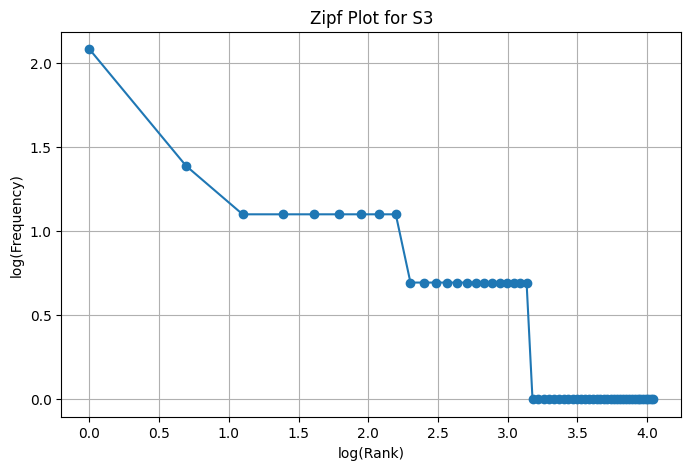


Top 5 bigrams in S1:
[(('.', 'i'), 8), (('.', 'the'), 4), (('.', 'this'), 4), (('this', 'is'), 4), (('is', 'urgent'), 4)]

Top 5 bigrams in S3:
[(("n't", 'know'), 3), (('know', 'changed'), 3), (('could', "n't"), 2), (("n't", 'connect'), 2), (('latest', 'update'), 2)]


In [18]:
# Your code

from collections import Counter
from nltk.util import bigrams
from nltk.stem import PorterStemmer
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Recalculate safely from the original tickets
results = df["Ticket_Text"].apply(process_ticket).tolist()

# S1: All tokens
S1 = [t for r in results for t in r["tokens"]]

# S2: No punctuation
S2 = [t for r in results for t in r["tokens"]
      if not is_punct(t)]

# S3: Final tokens
S3 = [t for r in results for t in r["final"]]

# S4: Porter-stemmed S3
porter = PorterStemmer()
S4 = [porter.stem(t) for t in S3]

# Statistics
stats = []

for name, tokens in [("S1", S1), ("S2", S2),
                     ("S3", S3), ("S4", S4)]:
    stats.append({
        "Corpus": name,
        "Tokens": len(tokens),
        "Unique Tokens": len(set(tokens)),
        "TTR": round(len(set(tokens)) / len(tokens), 4)
               if tokens else 0
    })

display(pd.DataFrame(stats))

# Top 10 words
print("\nTop 10 words in S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words in S3:")
print(Counter(S3).most_common(10))

# Log(rank) vs log(frequency)
frequencies = sorted(Counter(S3).values(), reverse=True)
ranks = np.arange(1, len(frequencies) + 1)

plt.figure(figsize=(8, 5))
plt.plot(np.log(ranks), np.log(frequencies), marker="o")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Zipf Plot for S3")
plt.grid(True)
plt.show()

# Top 5 bigrams
print("\nTop 5 bigrams in S1:")
print(Counter(bigrams(S1)).most_common(5))

print("\nTop 5 bigrams in S3:")
print(Counter(bigrams(S3)).most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*